In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# Same 69-cell layout; fixes are placed in the corresponding original cells.
# Run all cells from the beginning with the ORIGINAL CSV, not cleaned data.
# Dependencies: pandas, numpy, matplotlib, seaborn, scikit-learn >= 1.2.
# Old outputs were cleared. No improved R2 has been measured without your CSV.
RANDOM_STATE = 42
TARGET = 'price(in lakhs)'

In [2]:
# In Colab, upload Used Car Dataset.csv to /content, then Run all.
DATA_PATH = Path('/content/Used Car Dataset.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('Used Car Dataset.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(
        'Upload the ORIGINAL Used Car Dataset.csv or edit DATA_PATH in this cell.'
    )
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
raw_df = df.copy(deep=True)

# Only enter price corrections that you have checked against the source.
# Keys are ORIGINAL CSV row indices; values must be prices in lakhs.
VERIFIED_PRICE_CORRECTIONS = {}
for row_index, price in VERIFIED_PRICE_CORRECTIONS.items():
    if row_index not in df.index or not np.isfinite(price) or price <= 0:
        raise ValueError(f'Invalid verified price correction: {row_index}: {price}')
    df.loc[row_index, TARGET] = price
df

,Unnamed: 0,car_name,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownsership,transmission,manufacturing_year,mileage(kmpl),engine(cc),max_power(bhp),torque(Nm),price(in lakhs)
0,0,2017 Mercedes-Benz S-Class S400,Jul-17,Comprehensive,Petrol,5,56000,First Owner,Automatic,2017,7.81,2996.0,2996.0,333.0,63.75
1,1,2020 Nissan Magnite Turbo CVT XV Premium Opt BSVI,Jan-21,Comprehensive,Petrol,5,30615,First Owner,Automatic,2020,17.40,999.0,999.0,9863.0,8.99
2,2,2018 BMW X1 sDrive 20d xLine,Sep-18,Comprehensive,Diesel,5,24000,First Owner,Automatic,2018,20.68,1995.0,1995.0,188.0,23.75
3,3,2019 Kia Seltos GTX Plus,Dec-19,Comprehensive,Petrol,5,18378,First Owner,Manual,2019,16.50,1353.0,1353.0,13808.0,13.56
4,4,2019 Skoda Superb LK 1.8 TSI AT,Aug-19,Comprehensive,Petrol,5,44900,First Owner,Automatic,2019,14.67,1798.0,1798.0,17746.0,24.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,1548,2020 Hyundai Creta SX Opt Diesel AT BSVI,Aug-20,Comprehensive,Diesel,5,35000,First Owner,Automatic,2020,1493.00,11345.0,11345.0,250.0,17.41
1549,1549,2022 Renault KWID 1.0 RXL Opt BSVI,2022,Third Party insurance,Petrol,5,10000,999 cc,2022,Power Steering,999.00,6706.0,6706.0,91.0,3.98
1550,1550,2017 Honda WR-V i-VTEC S,Jun-17,Comprehensive,Petrol,5,49000,First Owner,Manual,2017,17.50,1199.0,1199.0,887.0,5.85
1551,1551,2018 Volkswagen Polo 1.0 MPI Comfortline,May-18,Comprehensive,Petrol,5,40000,Second Owner,Manual,2018,18.78,999.0,999.0,75.0,4.75


In [3]:
df.shape

(1553, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1553 entries, 0 to 1552
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          1553 non-null   int64  
 1   car_name            1553 non-null   object 
 2   registration_year   1553 non-null   object 
 3   insurance_validity  1553 non-null   object 
 4   fuel_type           1553 non-null   object 
 5   seats               1553 non-null   int64  
 6   kms_driven          1553 non-null   int64  
 7   ownsership          1553 non-null   object 
 8   transmission        1553 non-null   object 
 9   manufacturing_year  1553 non-null   object 
 10  mileage(kmpl)       1550 non-null   float64
 11  engine(cc)          1550 non-null   float64
 12  max_power(bhp)      1550 non-null   float64
 13  torque(Nm)          1549 non-null   float64
 14  price(in lakhs)     1553 non-null   float64
dtypes: float64(5), int64(3), object(7)
memory usage: 182.1+

In [5]:
df.isna().sum()

,0
Unnamed: 0,0
car_name,0
registration_year,0
insurance_validity,0
fuel_type,0
seats,0
kms_driven,0
ownsership,0
transmission,0
manufacturing_year,0


In [6]:
sum(df.duplicated())

0

In [7]:
df.describe()

,Unnamed: 0,seats,kms_driven,mileage(kmpl),engine(cc),max_power(bhp),torque(Nm),price(in lakhs)
count,1553.000000,1553.000000,1553.000000,1550.000000,1.550000e+03,1.550000e+03,1.549000e+03,1553.000000
mean,776.000000,91.480361,52841.931101,236.927277,1.471857e+10,1.471857e+10,1.423989e+04,166.141494
std,448.456798,2403.424060,40067.800347,585.964295,2.185629e+11,2.185629e+11,9.666241e+04,3478.855090
min,0.000000,4.000000,620.000000,7.810000,5.000000e+00,5.000000e+00,5.000000e+00,1.000000
25%,388.000000,5.000000,30000.000000,16.342500,1.197000e+03,1.197000e+03,4.000000e+02,4.660000
50%,776.000000,5.000000,49134.000000,18.900000,1.462000e+03,1.462000e+03,1.173000e+03,7.140000
75%,1164.000000,5.000000,70000.000000,22.000000,1.995000e+03,1.995000e+03,8.850000e+03,17.000000
max,1552.000000,67000.000000,810000.000000,3996.000000,3.258640e+12,3.258640e+12,1.464800e+06,95000.000000


In [8]:
df.columns

Index(['Unnamed: 0', 'car_name', 'registration_year', 'insurance_validity',
       'fuel_type', 'seats', 'kms_driven', 'ownsership', 'transmission',
       'manufacturing_year', 'mileage(kmpl)', 'engine(cc)', 'max_power(bhp)',
       'torque(Nm)', 'price(in lakhs)'],
      dtype='object')

# Drop Unwanted columns

In [9]:
# max_power duplicates/misrepresents engine data in the supplied outputs.
df.drop(columns=['Unnamed: 0', 'max_power(bhp)'], errors='ignore', inplace=True)
# Check duplicates AFTER removing the CSV row-number column.
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print('Exact duplicate records removed:', duplicate_count)

Exact duplicate records removed: 420


# Preprocessing

In [10]:
df

,car_name,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownsership,transmission,manufacturing_year,mileage(kmpl),engine(cc),torque(Nm),price(in lakhs)
0,2017 Mercedes-Benz S-Class S400,Jul-17,Comprehensive,Petrol,5,56000,First Owner,Automatic,2017,7.81,2996.0,333.0,63.75
1,2020 Nissan Magnite Turbo CVT XV Premium Opt BSVI,Jan-21,Comprehensive,Petrol,5,30615,First Owner,Automatic,2020,17.40,999.0,9863.0,8.99
2,2018 BMW X1 sDrive 20d xLine,Sep-18,Comprehensive,Diesel,5,24000,First Owner,Automatic,2018,20.68,1995.0,188.0,23.75
3,2019 Kia Seltos GTX Plus,Dec-19,Comprehensive,Petrol,5,18378,First Owner,Manual,2019,16.50,1353.0,13808.0,13.56
4,2019 Skoda Superb LK 1.8 TSI AT,Aug-19,Comprehensive,Petrol,5,44900,First Owner,Automatic,2019,14.67,1798.0,17746.0,24.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2020 Hyundai Creta SX Opt Diesel AT BSVI,Aug-20,Comprehensive,Diesel,5,35000,First Owner,Automatic,2020,1493.00,11345.0,250.0,17.41
1549,2022 Renault KWID 1.0 RXL Opt BSVI,2022,Third Party insurance,Petrol,5,10000,999 cc,2022,Power Steering,999.00,6706.0,91.0,3.98
1550,2017 Honda WR-V i-VTEC S,Jun-17,Comprehensive,Petrol,5,49000,First Owner,Manual,2017,17.50,1199.0,887.0,5.85
1551,2018 Volkswagen Polo 1.0 MPI Comfortline,May-18,Comprehensive,Petrol,5,40000,Second Owner,Manual,2018,18.78,999.0,75.0,4.75


# Add Brand Column

In [11]:
# Preserve model/variant information, but separate the year from the name.
car_text = df['car_name'].fillna('').astype(str).str.strip()
name_without_year = car_text.str.replace(r'^\d{4}\s+', '', regex=True)
df['brand'] = name_without_year.str.split().str[0]
df.loc[name_without_year.str.startswith('Land Rover'), 'brand'] = 'Land Rover'
df['car_variant'] = name_without_year.replace('', np.nan)
df['model_year'] = pd.to_numeric(
    car_text.str.extract(r'^(\d{4})\b', expand=False), errors='coerce'
)

In [12]:
df

,car_name,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownsership,transmission,manufacturing_year,mileage(kmpl),engine(cc),torque(Nm),price(in lakhs),brand,car_variant,model_year
0,2017 Mercedes-Benz S-Class S400,Jul-17,Comprehensive,Petrol,5,56000,First Owner,Automatic,2017,7.81,2996.0,333.0,63.75,Mercedes-Benz,Mercedes-Benz S-Class S400,2017
1,2020 Nissan Magnite Turbo CVT XV Premium Opt BSVI,Jan-21,Comprehensive,Petrol,5,30615,First Owner,Automatic,2020,17.40,999.0,9863.0,8.99,Nissan,Nissan Magnite Turbo CVT XV Premium Opt BSVI,2020
2,2018 BMW X1 sDrive 20d xLine,Sep-18,Comprehensive,Diesel,5,24000,First Owner,Automatic,2018,20.68,1995.0,188.0,23.75,BMW,BMW X1 sDrive 20d xLine,2018
3,2019 Kia Seltos GTX Plus,Dec-19,Comprehensive,Petrol,5,18378,First Owner,Manual,2019,16.50,1353.0,13808.0,13.56,Kia,Kia Seltos GTX Plus,2019
4,2019 Skoda Superb LK 1.8 TSI AT,Aug-19,Comprehensive,Petrol,5,44900,First Owner,Automatic,2019,14.67,1798.0,17746.0,24.00,Skoda,Skoda Superb LK 1.8 TSI AT,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2020 Hyundai Creta SX Opt Diesel AT BSVI,Aug-20,Comprehensive,Diesel,5,35000,First Owner,Automatic,2020,1493.00,11345.0,250.0,17.41,Hyundai,Hyundai Creta SX Opt Diesel AT BSVI,2020
1549,2022 Renault KWID 1.0 RXL Opt BSVI,2022,Third Party insurance,Petrol,5,10000,999 cc,2022,Power Steering,999.00,6706.0,91.0,3.98,Renault,Renault KWID 1.0 RXL Opt BSVI,2022
1550,2017 Honda WR-V i-VTEC S,Jun-17,Comprehensive,Petrol,5,49000,First Owner,Manual,2017,17.50,1199.0,887.0,5.85,Honda,Honda WR-V i-VTEC S,2017
1551,2018 Volkswagen Polo 1.0 MPI Comfortline,May-18,Comprehensive,Petrol,5,40000,Second Owner,Manual,2018,18.78,999.0,75.0,4.75,Volkswagen,Volkswagen Polo 1.0 MPI Comfortline,2018


In [13]:
def extract_year(series):
    text = series.astype('string').str.strip()
    full_year = text.str.extract(r'\b((?:19|20)\d{2})\b', expand=False)
    short_year = pd.to_numeric(
        text.str.extract(r'^[A-Za-z]{3}-(\d{2})$', expand=False), errors='coerce'
    )
    # This dataset contains modern cars. Four-digit years stay unchanged.
    result = pd.to_numeric(full_year, errors='coerce').fillna(2000 + short_year)
    return result.astype(float)

df['registration_year'] = extract_year(df['registration_year'])

In [14]:
df

,car_name,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownsership,transmission,manufacturing_year,mileage(kmpl),engine(cc),torque(Nm),price(in lakhs),brand,car_variant,model_year
0,2017 Mercedes-Benz S-Class S400,2017.0,Comprehensive,Petrol,5,56000,First Owner,Automatic,2017,7.81,2996.0,333.0,63.75,Mercedes-Benz,Mercedes-Benz S-Class S400,2017
1,2020 Nissan Magnite Turbo CVT XV Premium Opt BSVI,2021.0,Comprehensive,Petrol,5,30615,First Owner,Automatic,2020,17.40,999.0,9863.0,8.99,Nissan,Nissan Magnite Turbo CVT XV Premium Opt BSVI,2020
2,2018 BMW X1 sDrive 20d xLine,2018.0,Comprehensive,Diesel,5,24000,First Owner,Automatic,2018,20.68,1995.0,188.0,23.75,BMW,BMW X1 sDrive 20d xLine,2018
3,2019 Kia Seltos GTX Plus,2019.0,Comprehensive,Petrol,5,18378,First Owner,Manual,2019,16.50,1353.0,13808.0,13.56,Kia,Kia Seltos GTX Plus,2019
4,2019 Skoda Superb LK 1.8 TSI AT,2019.0,Comprehensive,Petrol,5,44900,First Owner,Automatic,2019,14.67,1798.0,17746.0,24.00,Skoda,Skoda Superb LK 1.8 TSI AT,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2020 Hyundai Creta SX Opt Diesel AT BSVI,2020.0,Comprehensive,Diesel,5,35000,First Owner,Automatic,2020,1493.00,11345.0,250.0,17.41,Hyundai,Hyundai Creta SX Opt Diesel AT BSVI,2020
1549,2022 Renault KWID 1.0 RXL Opt BSVI,2022.0,Third Party insurance,Petrol,5,10000,999 cc,2022,Power Steering,999.00,6706.0,91.0,3.98,Renault,Renault KWID 1.0 RXL Opt BSVI,2022
1550,2017 Honda WR-V i-VTEC S,2017.0,Comprehensive,Petrol,5,49000,First Owner,Manual,2017,17.50,1199.0,887.0,5.85,Honda,Honda WR-V i-VTEC S,2017
1551,2018 Volkswagen Polo 1.0 MPI Comfortline,2018.0,Comprehensive,Petrol,5,40000,Second Owner,Manual,2018,18.78,999.0,75.0,4.75,Volkswagen,Volkswagen Polo 1.0 MPI Comfortline,2018


In [15]:
df['registration_year'].value_counts()

,count
registration_year,
2018.0,171
2017.0,141
2019.0,133
2016.0,103
2015.0,98
2020.0,96
2021.0,86
2014.0,80
2022.0,75


In [16]:
# Invalid text remains missing; do not learn a mode from the entire dataset.
# Broad validity bounds, not IQR rules: an old car is not automatically wrong.
latest_year = pd.Timestamp.today().year + 1
df['registration_year'] = df['registration_year'].where(
    df['registration_year'].between(1950, latest_year)
)

In [17]:
df['registration_year'] = pd.to_numeric(df['registration_year'])

In [18]:
df['registration_year'].dtype

dtype('float64')

In [19]:
cat_col = df.select_dtypes('object')
for i in cat_col:
  d = df[i].value_counts()
  print(d)
  print("--------------------------------------------------------------")

car_name
2015 Hyundai Grand i10 Magna            8
2014 Hyundai Grand i10 Sportz           6
2017 BMW X1 sDrive20d Expedition        6
2016 Hyundai Grand i10 Sportz           5
2018 Honda WR-V i-VTEC VX               5
                                       ..
2017 Mercedes-Benz S-Class S400         1
2018 Maruti Swift Dzire VXI             1
2021 Hyundai Venue SX Plus Turbo DCT    1
2014 Nissan Sunny XL CVT                1
2017 Honda Jazz 1.2 V i VTEC            1
Name: count, Length: 925, dtype: int64
--------------------------------------------------------------
insurance_validity
Comprehensive            790
Third Party insurance    233
Third Party               56
Zero Dep                  52
Petrol                     1
Not Available              1
Name: count, dtype: int64
--------------------------------------------------------------
fuel_type
Petrol     751
Diesel     364
CNG         17
5 Seats      1
Name: count, dtype: int64
-------------------------------------------------

In [20]:
# Save recoverable values BEFORE replacing malformed ownership/transmission.
# A value explicitly labelled '999 cc' can be recovered as engine capacity.
recovered_engine = pd.to_numeric(
    df['ownsership'].astype('string').str.extract(
        r'^\s*(\d+(?:\.\d+)?)\s*cc\s*$', expand=False
    ), errors='coerce'
).astype(float)
recovered_year = extract_year(df['transmission'])

valid_owners = [
    'First Owner', 'Second Owner', 'Third Owner',
    'Fourth Owner', 'Fifth Owner', 'Sixth Owner',
]
owner_text = df['ownsership'].astype('string').str.strip()
df['ownsership'] = owner_text.where(owner_text.isin(valid_owners)).astype(object)
df['ownsership'] = df['ownsership'].where(df['ownsership'].notna(), np.nan)

In [21]:
df.rename(columns={"ownsership":"ownership"},inplace=True)

In [22]:
df['ownership'].value_counts()

,count
ownership,
First Owner,922
Second Owner,167
Third Owner,18
Fifth Owner,1


In [23]:
# Validate category meaning; get_dummies alone would keep malformed values.
allowed_categories = {
    'transmission': ['Manual', 'Automatic'],
    'fuel_type': ['Petrol', 'Diesel', 'CNG', 'LPG', 'Electric', 'Hybrid'],
    'insurance_validity': ['Comprehensive', 'Third Party', 'Zero Dep'],
}
df['insurance_validity'] = df['insurance_validity'].replace({
    'Third Party insurance': 'Third Party', 'Not Available': np.nan
})
for column, allowed in allowed_categories.items():
    text = df[column].astype('string').str.strip()
    df[column] = text.where(text.isin(allowed)).astype(object)
    df[column] = df[column].where(df[column].notna(), np.nan)

In [24]:
df['transmission'].value_counts()

,count
transmission,
Manual,646
Automatic,462


In [25]:
df.manufacturing_year.value_counts()

,count
manufacturing_year,
2018,172
2017,134
2019,133
2016,101
2015,98
2020,94
2021,88
2014,79
2022,66


In [26]:
# Recover a four-digit year displaced into transmission when present.
# Do not guess manufacturing year from registration year or the overall mode.
df['manufacturing_year'] = extract_year(df['manufacturing_year'])
df['manufacturing_year'] = df['manufacturing_year'].fillna(recovered_year)
df['manufacturing_year'] = df['manufacturing_year'].where(
    df['manufacturing_year'].between(1950, latest_year)
)
# Model year is retained separately: it need not equal manufacturing year.
df['model_year'] = df['model_year'].where(df['model_year'].between(1950, latest_year))

In [27]:
df['manufacturing_year'].value_counts()

,count
manufacturing_year,
2018.0,174
2017.0,142
2019.0,133
2016.0,102
2015.0,99
2020.0,95
2021.0,90
2014.0,82
2022.0,68


In [28]:
df.dtypes

,0
car_name,object
registration_year,float64
insurance_validity,object
fuel_type,object
seats,int64
kms_driven,int64
ownership,object
transmission,object
manufacturing_year,float64
mileage(kmpl),float64


# HAndle missing Values

In [29]:
df.isna().sum()

,0
car_name,0
registration_year,1
insurance_validity,2
fuel_type,1
seats,0
kms_driven,0
ownership,25
transmission,25
manufacturing_year,1
mileage(kmpl),2


In [30]:
numx = [
    'registration_year', 'seats', 'kms_driven', 'manufacturing_year',
    'mileage(kmpl)', 'engine(cc)', 'torque(Nm)', 'model_year', TARGET
]

In [31]:
for column in numx:
    df[column] = pd.to_numeric(df[column], errors='coerce')
df[numx] = df[numx].replace([np.inf, -np.inf], np.nan)

In [32]:
num_col = df.select_dtypes(include='number')

In [33]:
# Feature imputation is fitted on training folds inside the pipeline later.
# A missing/non-positive target cannot train a price model; never impute it.
invalid_target = df[TARGET].isna() | (df[TARGET] <= 0)
excluded_target_rows = df.loc[invalid_target].copy()
print('Rows excluded for missing/non-positive target:', int(invalid_target.sum()))
df = df.loc[~invalid_target].copy()
original_prices = df[TARGET].copy()

# Review, do not silently divide/delete unusually large positive prices.
# 1,000 lakh is a REVIEW threshold, not an automatic correction rule.
suspicious_prices = df.loc[df[TARGET] > 1000, ['car_name', TARGET]]
if not suspicious_prices.empty:
    print('REVIEW: prices above 1,000 lakh. Check units against the source.')
    print('They remain unchanged; incorrect labels can dominate R2.')
    display(suspicious_prices)
print('Missing features will be handled inside each training fold.')

Rows excluded for missing/non-positive target: 0
REVIEW: prices above 1,000 lakh. Check units against the source.
They remain unchanged; incorrect labels can dominate R2.


,car_name,price(in lakhs)
173,2011 Ford Figo Petrol EXI,70000.0
1277,2009 Maruti Alto 800 LXi,95000.0


Missing features will be handled inside each training fold.


In [34]:
df.isna().sum()

,0
car_name,0
registration_year,1
insurance_validity,2
fuel_type,1
seats,0
kms_driven,0
ownership,25
transmission,25
manufacturing_year,1
mileage(kmpl),2


In [35]:
df

,car_name,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownership,transmission,manufacturing_year,mileage(kmpl),engine(cc),torque(Nm),price(in lakhs),brand,car_variant,model_year
0,2017 Mercedes-Benz S-Class S400,2017.0,Comprehensive,Petrol,5,56000,First Owner,Automatic,2017.0,7.81,2996.0,333.0,63.75,Mercedes-Benz,Mercedes-Benz S-Class S400,2017
1,2020 Nissan Magnite Turbo CVT XV Premium Opt BSVI,2021.0,Comprehensive,Petrol,5,30615,First Owner,Automatic,2020.0,17.40,999.0,9863.0,8.99,Nissan,Nissan Magnite Turbo CVT XV Premium Opt BSVI,2020
2,2018 BMW X1 sDrive 20d xLine,2018.0,Comprehensive,Diesel,5,24000,First Owner,Automatic,2018.0,20.68,1995.0,188.0,23.75,BMW,BMW X1 sDrive 20d xLine,2018
3,2019 Kia Seltos GTX Plus,2019.0,Comprehensive,Petrol,5,18378,First Owner,Manual,2019.0,16.50,1353.0,13808.0,13.56,Kia,Kia Seltos GTX Plus,2019
4,2019 Skoda Superb LK 1.8 TSI AT,2019.0,Comprehensive,Petrol,5,44900,First Owner,Automatic,2019.0,14.67,1798.0,17746.0,24.00,Skoda,Skoda Superb LK 1.8 TSI AT,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2020 Hyundai Creta SX Opt Diesel AT BSVI,2020.0,Comprehensive,Diesel,5,35000,First Owner,Automatic,2020.0,1493.00,11345.0,250.0,17.41,Hyundai,Hyundai Creta SX Opt Diesel AT BSVI,2020
1549,2022 Renault KWID 1.0 RXL Opt BSVI,2022.0,Third Party,Petrol,5,10000,NaN,NaN,2022.0,999.00,6706.0,91.0,3.98,Renault,Renault KWID 1.0 RXL Opt BSVI,2022
1550,2017 Honda WR-V i-VTEC S,2017.0,Comprehensive,Petrol,5,49000,First Owner,Manual,2017.0,17.50,1199.0,887.0,5.85,Honda,Honda WR-V i-VTEC S,2017
1551,2018 Volkswagen Polo 1.0 MPI Comfortline,2018.0,Comprehensive,Petrol,5,40000,Second Owner,Manual,2018.0,18.78,999.0,75.0,4.75,Volkswagen,Volkswagen Polo 1.0 MPI Comfortline,2018


# Outlierss

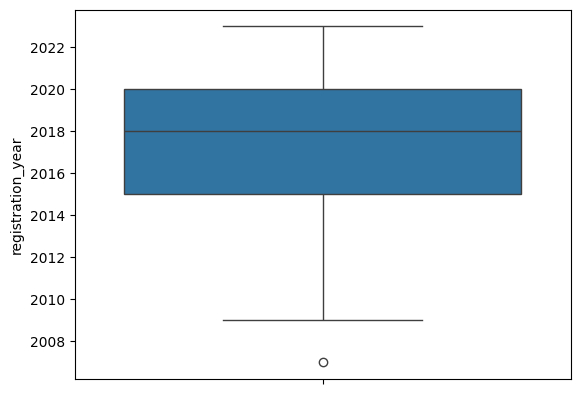

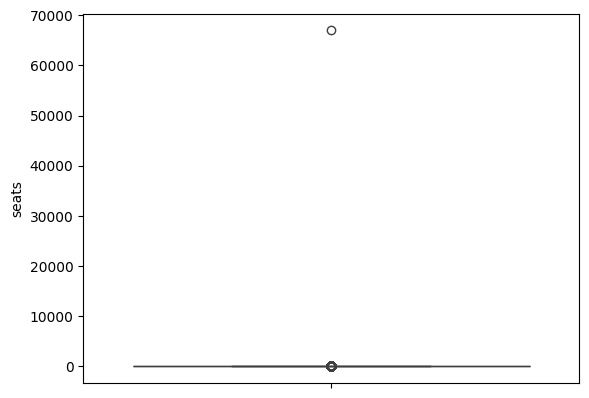

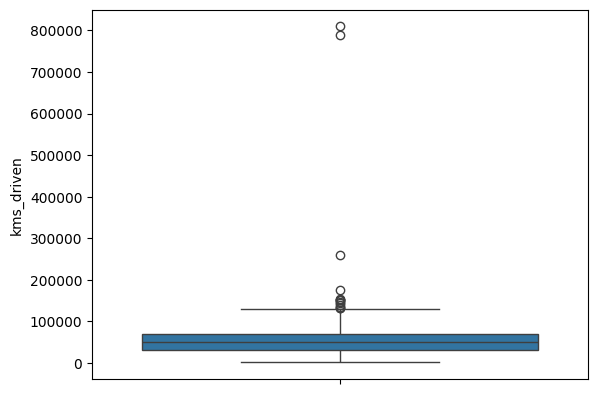

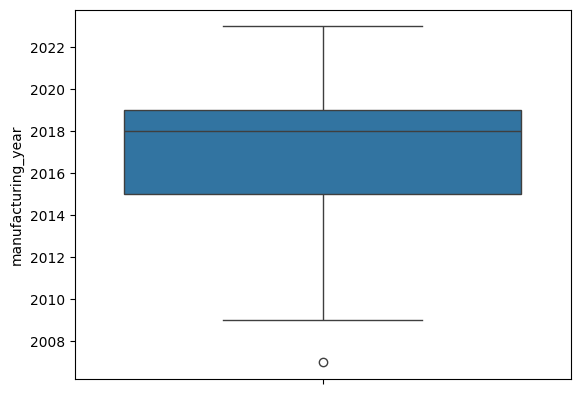

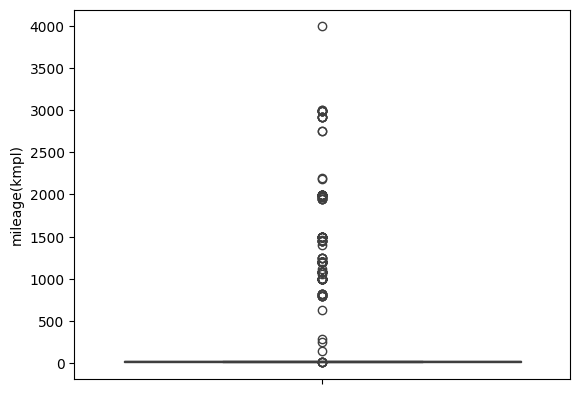

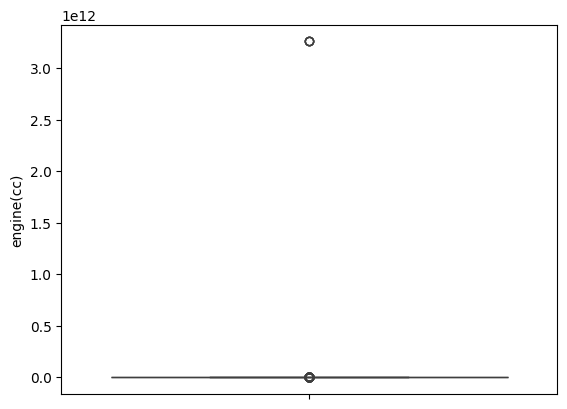

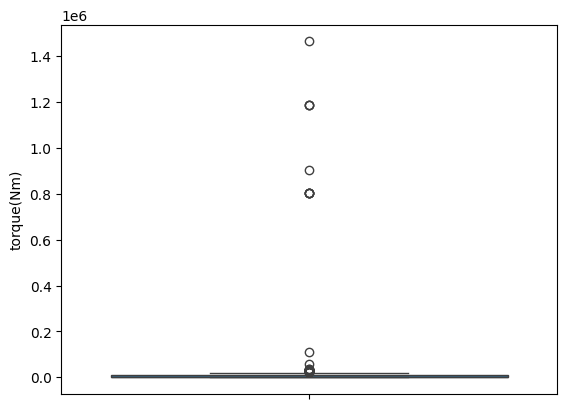

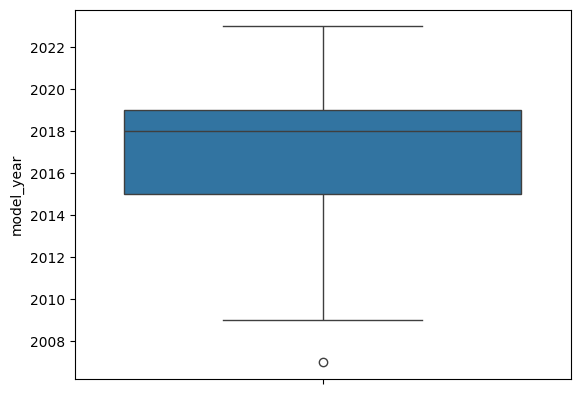

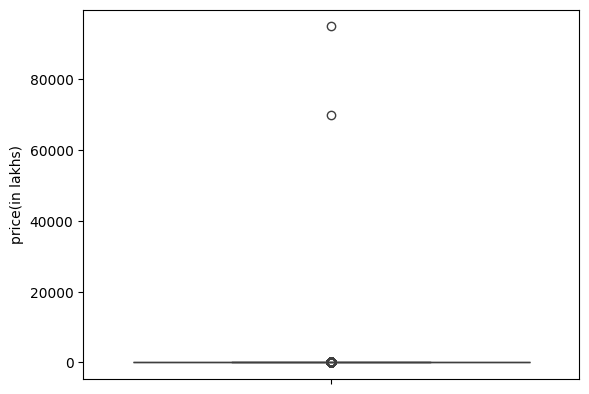

In [36]:
for i in numx:
  sns.boxplot(data=df,y=i)
  plt.show()

# HAndle Outliers

In [37]:
# Keep seats in validation, and exclude the target from feature cleaning.
numx = [column for column in numx if column != TARGET]

In [38]:
numx

['registration_year',
 'seats',
 'kms_driven',
 'manufacturing_year',
 'mileage(kmpl)',
 'engine(cc)',
 'torque(Nm)',
 'model_year']

In [39]:
# Do NOT replace IQR outliers with the median. Price variation is real.
# Broad passenger-car validity checks; these bounds are assumptions to review.
validation_bounds = {
    'seats': (1, 12),
    'kms_driven': (0, 2_000_000),
    'mileage(kmpl)': (1, 60),
    'engine(cc)': (300, 8500),
}
# Mileage holding 999/1493/... is evidence of displaced specification fields.
# In those rows, engine values can actually be power values without decimals.
displaced_specs = df['mileage(kmpl)'] > 100
df.loc[displaced_specs, 'engine(cc)'] = np.nan
valid_recovered_engine = recovered_engine.where(recovered_engine.between(300, 8500))
df['engine(cc)'] = valid_recovered_engine.combine_first(df['engine(cc)']).reindex(df.index)

invalid_counts = {}
for column, (lower, upper) in validation_bounds.items():
    invalid = df[column].notna() & ~df[column].between(lower, upper)
    if column == 'seats':
        invalid |= df[column].notna() & (df[column] % 1 != 0)
    invalid_counts[column] = int(invalid.sum())
    df.loc[invalid, column] = np.nan

# The saved data mixes implausible torque values and apparently displaced
# power values. Do not guess a /10 or /100 conversion. Exclude this feature
# until the original source verifies its values and units.
df.drop(columns=['torque(Nm)'], inplace=True)
numx = [column for column in numx if column != 'torque(Nm)']
pd.testing.assert_series_equal(df[TARGET], original_prices)
print('Invalid feature values marked missing:', invalid_counts)
print('Target prices preserved; unreliable torque excluded.')

Invalid feature values marked missing: {'seats': 1, 'kms_driven': 0, 'mileage(kmpl)': 159, 'engine(cc)': 1}
Target prices preserved; unreliable torque excluded.


# Box Plot

<Axes: >

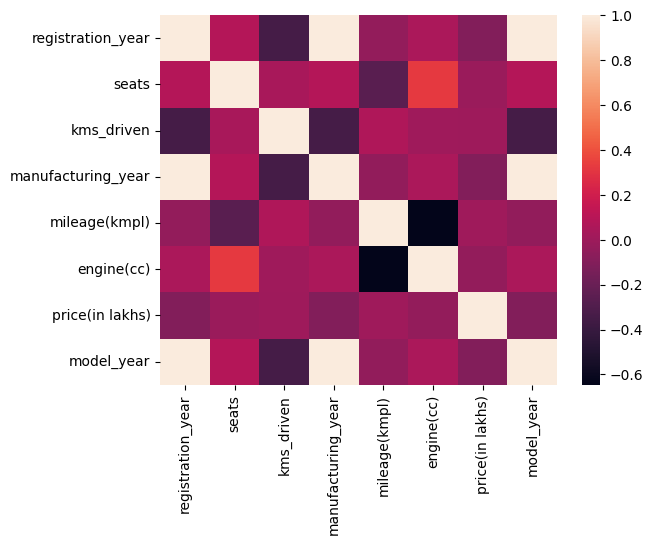

In [40]:
sns.heatmap(df.corr(numeric_only=True))

In [41]:
df.corr(numeric_only=True)

,registration_year,seats,kms_driven,manufacturing_year,mileage(kmpl),engine(cc),price(in lakhs),model_year
registration_year,1.000000,0.082258,-0.348355,0.995645,-0.040104,0.048642,-0.100917,0.995645
seats,0.082258,1.000000,0.039180,0.086490,-0.265485,0.324207,-0.012239,0.086490
kms_driven,-0.348355,0.039180,1.000000,-0.347330,0.062562,0.005009,-0.000426,-0.345307
manufacturing_year,0.995645,0.086490,-0.347330,1.000000,-0.042055,0.052866,-0.100621,1.000000
mileage(kmpl),-0.040104,-0.265485,0.062562,-0.042055,1.000000,-0.646164,0.009590,-0.042055
engine(cc),0.048642,0.324207,0.005009,0.052866,-0.646164,1.000000,-0.039684,0.052866
price(in lakhs),-0.100917,-0.012239,-0.000426,-0.100621,0.009590,-0.039684,1.000000,-0.100480
model_year,0.995645,0.086490,-0.345307,1.000000,-0.042055,0.052866,-0.100480,1.000000


In [42]:
# Keep kms_driven and mileage: low Pearson correlation alone is not a reason
# to remove them, especially for nonlinear tree models.
df.drop(columns=['car_name'], inplace=True)
# car_variant retains the name without the leading year; model_year is numeric.

In [43]:
df

,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownership,transmission,manufacturing_year,mileage(kmpl),engine(cc),price(in lakhs),brand,car_variant,model_year
0,2017.0,Comprehensive,Petrol,5.0,56000.0,First Owner,Automatic,2017.0,7.81,2996.0,63.75,Mercedes-Benz,Mercedes-Benz S-Class S400,2017
1,2021.0,Comprehensive,Petrol,5.0,30615.0,First Owner,Automatic,2020.0,17.40,999.0,8.99,Nissan,Nissan Magnite Turbo CVT XV Premium Opt BSVI,2020
2,2018.0,Comprehensive,Diesel,5.0,24000.0,First Owner,Automatic,2018.0,20.68,1995.0,23.75,BMW,BMW X1 sDrive 20d xLine,2018
3,2019.0,Comprehensive,Petrol,5.0,18378.0,First Owner,Manual,2019.0,16.50,1353.0,13.56,Kia,Kia Seltos GTX Plus,2019
4,2019.0,Comprehensive,Petrol,5.0,44900.0,First Owner,Automatic,2019.0,14.67,1798.0,24.00,Skoda,Skoda Superb LK 1.8 TSI AT,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2020.0,Comprehensive,Diesel,5.0,35000.0,First Owner,Automatic,2020.0,NaN,NaN,17.41,Hyundai,Hyundai Creta SX Opt Diesel AT BSVI,2020
1549,2022.0,Third Party,Petrol,5.0,10000.0,NaN,NaN,2022.0,NaN,999.0,3.98,Renault,Renault KWID 1.0 RXL Opt BSVI,2022
1550,2017.0,Comprehensive,Petrol,5.0,49000.0,First Owner,Manual,2017.0,17.50,1199.0,5.85,Honda,Honda WR-V i-VTEC S,2017
1551,2018.0,Comprehensive,Petrol,5.0,40000.0,Second Owner,Manual,2018.0,18.78,999.0,4.75,Volkswagen,Volkswagen Polo 1.0 MPI Comfortline,2018


In [44]:
df

,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownership,transmission,manufacturing_year,mileage(kmpl),engine(cc),price(in lakhs),brand,car_variant,model_year
0,2017.0,Comprehensive,Petrol,5.0,56000.0,First Owner,Automatic,2017.0,7.81,2996.0,63.75,Mercedes-Benz,Mercedes-Benz S-Class S400,2017
1,2021.0,Comprehensive,Petrol,5.0,30615.0,First Owner,Automatic,2020.0,17.40,999.0,8.99,Nissan,Nissan Magnite Turbo CVT XV Premium Opt BSVI,2020
2,2018.0,Comprehensive,Diesel,5.0,24000.0,First Owner,Automatic,2018.0,20.68,1995.0,23.75,BMW,BMW X1 sDrive 20d xLine,2018
3,2019.0,Comprehensive,Petrol,5.0,18378.0,First Owner,Manual,2019.0,16.50,1353.0,13.56,Kia,Kia Seltos GTX Plus,2019
4,2019.0,Comprehensive,Petrol,5.0,44900.0,First Owner,Automatic,2019.0,14.67,1798.0,24.00,Skoda,Skoda Superb LK 1.8 TSI AT,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2020.0,Comprehensive,Diesel,5.0,35000.0,First Owner,Automatic,2020.0,NaN,NaN,17.41,Hyundai,Hyundai Creta SX Opt Diesel AT BSVI,2020
1549,2022.0,Third Party,Petrol,5.0,10000.0,NaN,NaN,2022.0,NaN,999.0,3.98,Renault,Renault KWID 1.0 RXL Opt BSVI,2022
1550,2017.0,Comprehensive,Petrol,5.0,49000.0,First Owner,Manual,2017.0,17.50,1199.0,5.85,Honda,Honda WR-V i-VTEC S,2017
1551,2018.0,Comprehensive,Petrol,5.0,40000.0,Second Owner,Manual,2018.0,18.78,999.0,4.75,Volkswagen,Volkswagen Polo 1.0 MPI Comfortline,2018


# encode

In [45]:
cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
cols

['insurance_validity',
 'fuel_type',
 'ownership',
 'transmission',
 'brand',
 'car_variant']

In [46]:
# Define the encoder now; fit it inside the model pipeline AFTER splitting.
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
# This safely handles a car variant that is absent from a training fold.

In [47]:
df

,registration_year,insurance_validity,fuel_type,seats,kms_driven,ownership,transmission,manufacturing_year,mileage(kmpl),engine(cc),price(in lakhs),brand,car_variant,model_year
0,2017.0,Comprehensive,Petrol,5.0,56000.0,First Owner,Automatic,2017.0,7.81,2996.0,63.75,Mercedes-Benz,Mercedes-Benz S-Class S400,2017
1,2021.0,Comprehensive,Petrol,5.0,30615.0,First Owner,Automatic,2020.0,17.40,999.0,8.99,Nissan,Nissan Magnite Turbo CVT XV Premium Opt BSVI,2020
2,2018.0,Comprehensive,Diesel,5.0,24000.0,First Owner,Automatic,2018.0,20.68,1995.0,23.75,BMW,BMW X1 sDrive 20d xLine,2018
3,2019.0,Comprehensive,Petrol,5.0,18378.0,First Owner,Manual,2019.0,16.50,1353.0,13.56,Kia,Kia Seltos GTX Plus,2019
4,2019.0,Comprehensive,Petrol,5.0,44900.0,First Owner,Automatic,2019.0,14.67,1798.0,24.00,Skoda,Skoda Superb LK 1.8 TSI AT,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2020.0,Comprehensive,Diesel,5.0,35000.0,First Owner,Automatic,2020.0,NaN,NaN,17.41,Hyundai,Hyundai Creta SX Opt Diesel AT BSVI,2020
1549,2022.0,Third Party,Petrol,5.0,10000.0,NaN,NaN,2022.0,NaN,999.0,3.98,Renault,Renault KWID 1.0 RXL Opt BSVI,2022
1550,2017.0,Comprehensive,Petrol,5.0,49000.0,First Owner,Manual,2017.0,17.50,1199.0,5.85,Honda,Honda WR-V i-VTEC S,2017
1551,2018.0,Comprehensive,Petrol,5.0,40000.0,Second Owner,Manual,2018.0,18.78,999.0,4.75,Volkswagen,Volkswagen Polo 1.0 MPI Comfortline,2018


In [48]:
x = df.drop(columns=['price(in lakhs)'])
y = df['price(in lakhs)']

In [49]:
y

,price(in lakhs)
0,63.75
1,8.99
2,23.75
3,13.56
4,24.00
...,...
1548,17.41
1549,3.98
1550,5.85
1551,4.75


In [50]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Train:', x_train.shape, '| Test:', x_test.shape)
# Do not change the seed or choose a model using the test R2.

Train: (906, 13) | Test: (227, 13)


# Scaling

In [51]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_columns = x_train.select_dtypes(include='number').columns.tolist()
categorical_columns = x_train.select_dtypes(include=['object', 'string']).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True,
                              keep_empty_features=True)),
    ('scaler', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown',
                              keep_empty_features=True)),
    ('encoder', encoder),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns),
])
# Leave x_train/x_test as DataFrames. GridSearchCV clones and fits the
# entire pipeline in each fold, including imputation, encoding and scaling.

In [52]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.base import clone

# Your original algorithm remains as the baseline, with corrected preprocessing.
model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', LinearRegression()),
])
model.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['registration_year', 'seats',
                                                   'kms_driven',
                                                   'manufacturing_year',
                                                   'mileage(kmpl)',
                                                   'engine(cc)',
                                                   'model_year']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 keep_empty_features=True,
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['insurance_validity',
                                                   'fuel_type', 'ownership',
                                                   'transmission', 'brand',
                                                   'car_variant'])])),
                ('regressor', LinearRegression())])

In [53]:
# Compare the baseline on TRAINING folds before opening the test set.
from sklearn.model_selection import KFold, cross_validate
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline_cv = cross_validate(
    model, x_train, y_train, cv=cv,
    scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'},
    n_jobs=-1, error_score='raise'
)

In [54]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    r2_score, mean_absolute_percentage_error,
)

print('Linear Regression baseline (training cross-validation)')
print(f"Mean CV R2: {baseline_cv['test_r2'].mean():.4f}")
print(f"CV R2 standard deviation: {baseline_cv['test_r2'].std():.4f}")
print(f"Mean CV MAE: {-baseline_cv['test_mae'].mean():.2f} lakh")
print('Final test metrics are calculated only after model selection below.')

Linear Regression baseline (training cross-validation)
Mean CV R2: 0.3818
CV R2 standard deviation: 0.2388
Mean CV MAE: 6.55 lakh
Final test metrics are calculated only after model selection below.


In [55]:
from sklearn.model_selection import GridSearchCV

In [56]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

# Tree ensembles capture nonlinear effects; Ridge stabilizes linear fits.
# CV also includes LinearRegression, so a more complex model is not forced.
model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', Ridge()),
])

In [57]:
params = [
    {
        'regressor': [LinearRegression()],
        'regressor__fit_intercept': [True],
    },
    {
        'regressor': [Ridge()],
        'regressor__alpha': [0.1, 1.0, 10.0],
    },
    {
        'regressor': [RandomForestRegressor(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=1
        )],
        'regressor__max_depth': [None, 16],
        'regressor__min_samples_leaf': [1, 2, 4],
    },
    {
        'regressor': [ExtraTreesRegressor(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=1
        )],
        'regressor__max_depth': [None, 16],
        'regressor__min_samples_leaf': [1, 2, 4],
    },
]
# 16 combinations x 5 folds = 80 fits. Runtime depends on your computer.

In [58]:
grd = GridSearchCV(
    model, params, cv=cv, scoring='r2',
    n_jobs=-1, refit=True, return_train_score=True,
    error_score='raise', verbose=1
)

In [59]:
grd.fit(x_train,y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('numeric',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(add_indicator=True,
                                                                                                        keep_empty_features=True,
                                                                                                        strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['registration_year',
                                                                          'seats',
                                                                          'kms_driven',
                                                                          'manu...
                         {'regressor': [RandomForestRegressor(n_estimators=200,
                                                              n_jobs=1,
                                                              random_state=42)],
                          'regressor__max_depth': [None, 16],
                          'regressor__min_samples_leaf': [1, 2, 4]},
                         {'regressor': [ExtraTreesRegressor(n_estimators=200,
                                                            n_jobs=1,
                                                            random_state=42)],
                          'regressor__max_depth': [None, 16],
                          'regressor__min_samples_leaf': [1, 2, 4]}],
             return_train_score=True, scoring='r2', verbose=1)

In [60]:
print('Best Parameters:', grd.best_params_)
print(f'Best CV R2: {grd.best_score_:.4f}')
cv_results = pd.DataFrame(grd.cv_results_)
display(cv_results[[
    'rank_test_score', 'mean_test_score', 'std_test_score',
    'mean_train_score', 'params'
]].sort_values('rank_test_score').head(10))

best_model = grd.best_estimator_
y_pred = best_model.predict(x_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
print('\nFinal held-out test results — original price units')
print(f'MAE: {mae:.2f} lakh')
print(f'RMSE: {np.sqrt(mse):.2f} lakh')
print(f'MSE: {mse:.2f} lakh squared')
print(f'MAPE: {mape * 100:.2f}%')
print(f'Test R2: {r2:.4f}')
predictions = pd.DataFrame({
    'actual_price_lakh': y_test,
    'predicted_price_lakh': y_pred,
    'absolute_error_lakh': np.abs(y_test - y_pred),
})
display(predictions.head(10))
print('Selected by training CV only. A higher test R2 is not guaranteed.')
print('The old 0.55 R2 used altered prices, so it is not directly comparable.')
if not suspicious_prices.empty:
    print('Source price/unit review is still needed for the flagged rows.')

Best Parameters: {'regressor': RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=42), 'regressor__max_depth': 16, 'regressor__min_samples_leaf': 2}
Best CV R2: 0.6703


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
8,1,0.670313,0.056906,0.908381,{'regressor': RandomForestRegressor(n_estimato...
5,2,0.669358,0.056622,0.908281,{'regressor': RandomForestRegressor(n_estimato...
11,3,0.667698,0.046585,0.957290,{'regressor': ExtraTreesRegressor(n_estimators...
4,4,0.667164,0.036729,0.951960,{'regressor': RandomForestRegressor(n_estimato...
7,5,0.666583,0.036696,0.950980,{'regressor': RandomForestRegressor(n_estimato...
14,6,0.663508,0.047993,0.955092,{'regressor': ExtraTreesRegressor(n_estimators...
9,7,0.651265,0.060192,0.820771,{'regressor': RandomForestRegressor(n_estimato...
6,8,0.651256,0.060190,0.820741,{'regressor': RandomForestRegressor(n_estimato...
12,9,0.649139,0.053397,0.851991,{'regressor': ExtraTreesRegressor(n_estimators...
15,10,0.646991,0.053127,0.852150,{'regressor': ExtraTreesRegressor(n_estimators...



Final held-out test results — original price units
MAE: 730.80 lakh
RMSE: 7832.02 lakh
MSE: 61340547.31 lakh squared
MAPE: 69.28%
Test R2: -0.0089


,actual_price_lakh,predicted_price_lakh,absolute_error_lakh
1193,8.50,16.929171,8.429171
1311,2.25,4.688893,2.438893
675,12.75,10.180167,2.569833
752,4.63,6.332044,1.702044
1155,4.40,3.218938,1.181062
169,8.24,8.228920,0.011080
869,7.45,8.838173,1.388173
76,2.00,1.877797,0.122203
1531,2.80,3.038835,0.238835
1226,4.96,4.639676,0.320324


Selected by training CV only. A higher test R2 is not guaranteed.
The old 0.55 R2 used altered prices, so it is not directly comparable.
Source price/unit review is still needed for the flagged rows.
